# 01 — Data download and cleaning

Goal: a clean, aligned table of daily log returns for **VAS.AX** (Vanguard Australian Shares) and
**VGS.AX** (Vanguard MSCI Index International Shares, unhedged), both ASX-listed and priced in AUD.
Every cleaning step below is documented for Task 1 of the report.

Outputs: `data/raw/prices_<download date>.csv`, `data/clean/log_returns.csv`,
`tables/data_summary.csv` / `.tex` (Table 1), `figures/fig01_prices.*`, `figures/fig02_returns.*`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

import config as cfg
from src import gbm_utils as gu

gu.set_style()
pd.set_option("display.width", 120)
KEYS = list(cfg.TICKERS)                       # ["AU", "GL"]
TK = [cfg.TICKERS[k] for k in KEYS]            # ["VAS.AX", "VGS.AX"]

## 1. Download

Daily data from Yahoo Finance via `yfinance`, with `auto_adjust=False` so both `Close` and `Adj Close`
are kept. The untouched download is saved to `data/raw/` with the download date in the filename and
re-used on later runs (delete it to re-download). `end` is exclusive in `yfinance`, so the download day
itself — still trading when the data was pulled — is excluded.

In [2]:
raw, downloaded_now = gu.load_or_download_prices(TK, cfg.DOWNLOAD_START, cfg.END, cfg.DOWNLOAD_DATE)
raw_path = gu.RAW_DIR / f"prices_{cfg.DOWNLOAD_DATE}.csv"

print("yfinance call:")
print(f"  yf.download({TK}, start='{cfg.DOWNLOAD_START}', end='{cfg.END}', "
      "auto_adjust=False, actions=True, progress=False)")
print(f"Raw file: {raw_path.relative_to(ROOT)}  ({'downloaded now' if downloaded_now else 'loaded from cache'})")
print(f"Fields: {sorted(raw.columns.get_level_values(0).unique())}")
print(f"Raw rows (union of trading days): {len(raw)}")

yfinance call:
  yf.download(['VAS.AX', 'VGS.AX'], start='2000-01-01', end='2026-11-10', auto_adjust=False, actions=True, progress=False)
Raw file: data/raw/prices_2026-11-10.csv  (loaded from cache)
Fields: ['Adj Close', 'Capital Gains', 'Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']
Raw rows (union of trading days): 4433


## 2. Metadata of the raw download

In [3]:
px_raw = raw[cfg.PRICE_FIELD][TK]
meta = pd.DataFrame({
    "ticker": TK,
    "download_date": cfg.DOWNLOAD_DATE,
    "raw_first_date": [px_raw[t].first_valid_index().date() for t in TK],
    "raw_last_date": [px_raw[t].last_valid_index().date() for t in TK],
    "raw_n_obs": [int(px_raw[t].notna().sum()) for t in TK],
}, index=KEYS)
meta

,ticker,download_date,raw_first_date,raw_last_date,raw_n_obs
AU,VAS.AX,2026-11-10,2009-05-01,2026-11-09,4433
GL,VGS.AX,2026-11-10,2014-11-18,2026-11-09,3030


## 3. Price field

We use **Adj Close**, which Yahoo adjusts for distributions and splits, so it approximates a total-return
series (distributions reinvested on the ex-date). **Franking credits are not included**, so the Australian
total return is understated for an investor who can use them. The cell below shows how much the
adjustment matters over the common sample.

In [4]:
divs = raw["Dividends"][TK]
splits = raw["Stock Splits"][TK]
common_start = px_raw.dropna().index[0]
close = raw["Close"][TK].loc[common_start:].dropna()
adj = px_raw.loc[common_start:].dropna()
yrs = len(adj) / cfg.TRADING_DAYS
for k, t in zip(KEYS, TK):
    g_adj = np.log(adj[t].iloc[-1] / adj[t].iloc[0]) / yrs
    g_cls = np.log(close[t].iloc[-1] / close[t].iloc[0]) / yrs
    print(f"{t}: {int((divs[t].loc[common_start:] > 0).sum())} distributions, "
          f"{int((splits[t].loc[common_start:] > 0).sum())} splits since {common_start.date()}; "
          f"annualised log growth  Close {g_cls:6.2%}  vs  Adj Close {g_adj:6.2%}")

VAS.AX: 48 distributions, 0 splits since 2014-11-18; annualised log growth  Close  4.04%  vs  Adj Close  8.11%
VGS.AX: 48 distributions, 0 splits since 2014-11-18; annualised log growth  Close  9.66%  vs  Adj Close 12.24%


## 4. Align on common ASX trading days

Inner join of the two Adj Close series: keep only days on which both ETFs have a price.

In [5]:
px = px_raw.dropna(how="any").copy()
px.columns = KEYS
START, LAST = px.index[0], px.index[-1]

before_start = px_raw.loc[:START].iloc[:-1]                 # rows before VGS listed
after = px_raw.loc[START:]
one_missing = after[after.isna().any(axis=1)]                # gaps after the common start

print(f"First common trading day (START): {START.date()}   |   last close: {LAST.date()}")
print(f"Raw rows: {len(px_raw)}  ->  aligned rows: {len(px)}  (dropped {len(px_raw) - len(px)})")
print(f"  {len(before_start)} rows before {START.date()}: VAS trading, VGS not yet listed")
print(f"  {len(one_missing)} row(s) after START with one ticker missing:")
for d, row in one_missing.iterrows():
    print(f"    {d.date()}: missing {', '.join(row.index[row.isna()])}")

First common trading day (START): 2014-11-18   |   last close: 2026-11-09
Raw rows: 4433  ->  aligned rows: 3030  (dropped 1403)
  1402 rows before 2014-11-18: VAS trading, VGS not yet listed
  1 row(s) after START with one ticker missing:
    2024-05-10: missing VGS.AX


## 5. Data-quality checks

Missing values, non-positive prices, repeated prices (which give zero log returns), zero-volume days,
duplicated dates, unusually long calendar gaps, and absolute daily log returns above the threshold in
`config.py`. Large moves are listed with their dates for inspection against known events; nothing is deleted.

In [6]:
vol = raw["Volume"][TK].loc[px.index]
vol.columns = KEYS
rets = gu.log_returns(px)

checks = pd.DataFrame({
    "missing values": px.isna().sum(),
    "non-positive prices": (px <= 0).sum(),
    "repeated prices (zero returns)": (rets == 0).sum(),
    "longest run of identical prices": [gu.max_run_of_repeats(px[k]) for k in KEYS],
    "zero-volume days": (vol == 0).sum(),
    "duplicated dates": [int(px.index.duplicated().sum())] * 2,
    f"|log return| > {cfg.OUTLIER_THRESHOLD:.0%}": (rets.abs() > cfg.OUTLIER_THRESHOLD).sum(),
}).T
display(checks)

gaps = px.index.to_series().diff().dt.days
print(f"Longest gap between consecutive aligned dates: {int(gaps.max())} calendar days "
      f"(ending {gaps.idxmax().date()})")
print("Zero-volume days:", {k: [d.date().isoformat() for d in vol.index[vol[k] == 0]] for k in KEYS})

,AU,GL
missing values,0,0
non-positive prices,0,0
repeated prices (zero returns),16,32
longest run of identical prices,2,3
zero-volume days,0,4
duplicated dates,0,0
|log return| > 10%,0,0


Longest gap between consecutive aligned dates: 5 calendar days (ending 2014-12-29)
Zero-volume days: {'AU': [], 'GL': ['2014-11-18', '2014-11-19', '2014-11-20', '2014-12-31']}


In [7]:
# Largest absolute daily moves, for inspection against known market events
top = pd.concat({k: rets[k].abs().nlargest(5) for k in KEYS}, names=["etf", "date"])
top = pd.DataFrame({"log return": [rets.loc[d, k] for k, d in top.index]}, index=top.index)
in_covid = [pd.Timestamp(cfg.COVID_CRASH[0]) <= d <= pd.Timestamp(cfg.COVID_CRASH[1]) for _, d in top.index]
top["in COVID crash window"] = in_covid
print(f"Largest |log return|: AU {rets['AU'].abs().max():.2%} on {rets['AU'].abs().idxmax().date()}, "
      f"GL {rets['GL'].abs().max():.2%} on {rets['GL'].abs().idxmax().date()}")
top.style.format({"log return": "{:.2%}"})

Largest |log return|: AU 8.03% on 2020-03-16, GL 5.79% on 2025-04-10


All flagged items are kept: repeated prices and zero-volume days are genuine no-trade/unchanged days in the
exchange record, and the largest moves can be matched to dated market events. The checks are reported so
they can be discussed in the report rather than silently removed.

## 6. Daily log returns

$$X_k = \ln\left(\frac{S_{t_k}}{S_{t_{k-1}}}\right)$$

In [8]:
gu.CLEAN_DIR.mkdir(parents=True, exist_ok=True)
out = rets.copy()
out.index.name = "date"
out.to_csv(gu.CLEAN_DIR / "log_returns.csv", float_format="%.10f")
px.rename_axis("date").to_csv(gu.CLEAN_DIR / "prices_aligned.csv", float_format="%.6f")
print(f"Saved data/clean/log_returns.csv: {len(out)} returns x {out.shape[1]} ETFs, "
      f"{out.index[0].date()} to {out.index[-1].date()}")
print(f"Sample length T = n * dt = {len(out)} / {cfg.TRADING_DAYS} = {len(out) / cfg.TRADING_DAYS:.2f} years")
out.describe().T

Saved data/clean/log_returns.csv: 3029 returns x 2 ETFs, 2014-11-19 to 2026-11-09
Sample length T = n * dt = 3029 / 252 = 12.02 years


,count,mean,std,min,25%,50%,75%,max
AU,3029.0,0.000322,0.009231,-0.080348,-0.004290,0.000813,0.005408,0.058105
GL,3029.0,0.000486,0.008272,-0.056626,-0.003896,0.000584,0.005124,0.057912


## 7. Table 1 — data summary

In [9]:
notes = {}
for k, t in zip(KEYS, TK):
    parts = [f"Adj Close; inner join with {'VGS' if k == 'AU' else 'VAS'}"]
    if k == "AU":
        parts.append(f"{len(before_start)} pre-{START.year} rows dropped (VGS not listed)")
    for d, row in one_missing.iterrows():
        who = ", ".join(c.split(".")[0] for c in row.index[row.isna()])
        parts.append(f"{d.date()} dropped (no {who} price)")
    parts.append(f"{int(checks.loc['repeated prices (zero returns)', k])} zero returns kept")
    if checks.loc["zero-volume days", k]:
        parts.append(f"{int(checks.loc['zero-volume days', k])} zero-volume days kept")
    parts.append(f"no |X| > {cfg.OUTLIER_THRESHOLD:.0%}" if checks.loc[f"|log return| > {cfg.OUTLIER_THRESHOLD:.0%}", k] == 0
                 else f"{int(checks.loc[f'|log return| > {cfg.OUTLIER_THRESHOLD:.0%}', k])} |X| > {cfg.OUTLIER_THRESHOLD:.0%} kept")
    notes[k] = "; ".join(parts)

summary = meta.assign(
    name=[cfg.LABELS[k] for k in KEYS],
    start=START.date(), end=LAST.date(),
    n_prices=len(px), n_returns=len(rets),
    cleaning_notes=[notes[k] for k in KEYS],
)[["ticker", "name", "download_date", "raw_first_date", "raw_last_date", "raw_n_obs",
   "start", "end", "n_prices", "n_returns", "cleaning_notes"]]
gu.TAB_DIR.mkdir(parents=True, exist_ok=True)
summary.to_csv(gu.TAB_DIR / "data_summary.csv", index=False)

tex = summary[["ticker", "start", "end", "n_returns", "cleaning_notes"]].rename(columns={
    "ticker": "Ticker", "start": "Start", "end": "End", "n_returns": "$N$ returns",
    "cleaning_notes": "Cleaning notes"})
tex.to_latex(gu.TAB_DIR / "data_summary.tex", index=False, escape=False,
             column_format="llllp{7cm}",
             caption=f"Data summary. Source: Yahoo Finance via yfinance, downloaded {cfg.DOWNLOAD_DATE}.",
             label="tab:data")
with pd.option_context("display.max_colwidth", None):
    display(summary.T)

,AU,GL
ticker,VAS.AX,VGS.AX
name,Australia (VAS),Global ex-AU (VGS)
download_date,2026-11-10,2026-11-10
raw_first_date,2009-05-01,2014-11-18
raw_last_date,2026-11-09,2026-11-09
raw_n_obs,4433,3030
start,2014-11-18,2014-11-18
end,2026-11-09,2026-11-09
n_prices,3030,3030
n_returns,3029,3029


## 8. Figures

**Fig 1** shows both price series (Adj Close) rebased to 100 on the first common day, on a log scale, with
the COVID crash window shaded.

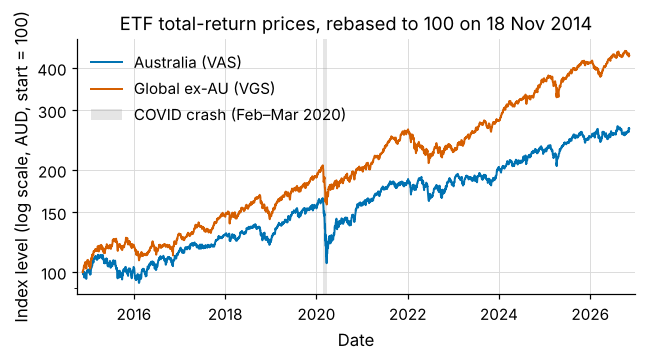

In [10]:
rebased = 100 * px / px.iloc[0]
fig, ax = plt.subplots(figsize=(6.0, 3.4))
for k in KEYS:
    ax.plot(rebased.index, rebased[k], color=cfg.COLORS[k], lw=1.3, label=cfg.LABELS[k])
gu.shade_period(ax, *cfg.COVID_CRASH, label="COVID crash (Feb–Mar 2020)")
ax.set_yscale("log")
ax.yaxis.set_major_locator(mticker.LogLocator(base=10, subs=[1, 1.5, 2, 3, 4, 5, 7]))
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%g"))
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_title(f"ETF total-return prices, rebased to 100 on {START:%d %b %Y}")
ax.set_xlabel("Date")
ax.set_ylabel("Index level (log scale, AUD, start = 100)")
ax.legend(loc="upper left")
ax.margins(x=0.01)
fig.tight_layout()
gu.savefig(fig, "fig01_prices")
plt.show()

**Fig 2** shows the daily log returns of each ETF over time, in two stacked panels with a shared x-axis and
a common y-scale.

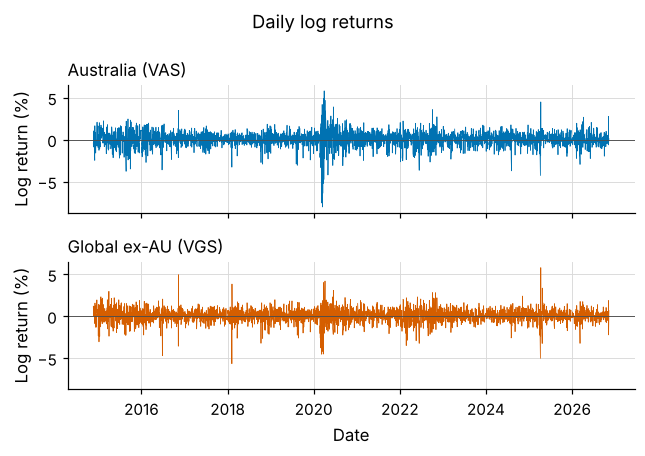

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(6.0, 4.2), sharex=True, sharey=True)
for ax, k in zip(axes, KEYS):
    ax.plot(rets.index, 100 * rets[k], color=cfg.COLORS[k], lw=0.5)
    ax.axhline(0, color="0.3", lw=0.6)
    ax.set_title(cfg.LABELS[k], loc="left", fontsize=11)
    ax.set_ylabel("Log return (%)")
axes[-1].set_xlabel("Date")
axes[0].margins(x=0.01)
fig.suptitle("Daily log returns", fontsize=12)
fig.tight_layout()
gu.savefig(fig, "fig02_returns")
plt.show()